### Preparing the dataset 

Use only the following columns:

* `'engine_displacement'`,
* `'horsepower'`,
* `'vehicle_weight'`,
* `'model_year'`,
* `'fuel_efficiency_mpg'`

In [1]:
import pandas as pd
df = pd.read_csv("car_fuel_efficiency_2026.csv")
df=df[['engine_displacement','horsepower','vehicle_weight','model_year','fuel_efficiency_mpg']]
df

,engine_displacement,horsepower,vehicle_weight,model_year,fuel_efficiency_mpg
0,2180,243.0,3870,2006,31.9
1,2390,272.0,4210,2008,31.3
2,2320,267.0,4240,1996,27.5
3,2130,258.0,4490,1989,28.5
4,2580,304.0,4510,1994,31.0
...,...,...,...,...,...
9995,2470,271.0,4690,2005,27.4
9996,2300,244.0,4370,1993,30.0
9997,2480,267.0,4590,2014,28.1
9998,2180,270.0,4450,2004,32.2


### EDA

* Look at the `fuel_efficiency_mpg` variable. Does it have a long tail? 


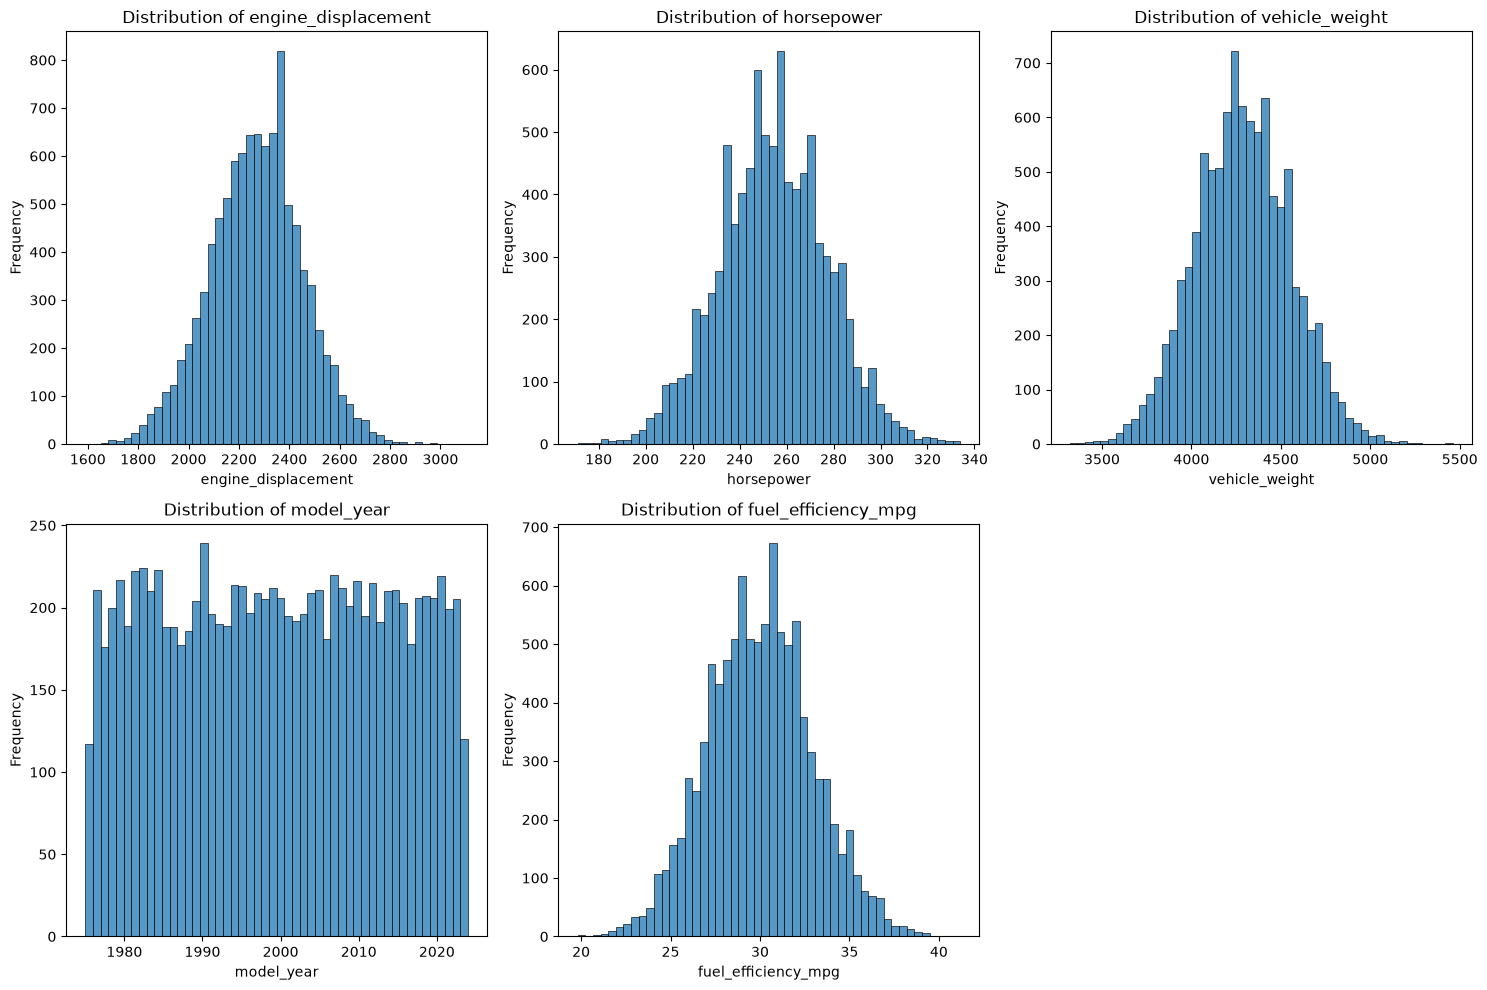

In [2]:
import matplotlib.pyplot as plt
import seaborn as sns

cols = ['engine_displacement','horsepower','vehicle_weight','model_year','fuel_efficiency_mpg']
plt.figure(figsize=(15, 10))

for i, col in enumerate(cols):
    plt.subplot(2, 3, i+1)
    sns.histplot(df[col], bins=50)
    plt.title(f'Distribution of {col}')
    plt.xlabel(col)
    plt.ylabel('Frequency')

plt.tight_layout()
plt.show()

<Axes: xlabel='fuel_efficiency_mpg', ylabel='Count'>

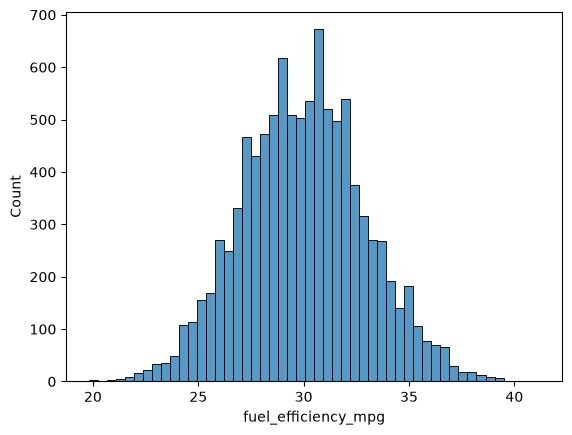

In [3]:
import seaborn as sns
sns.histplot(df.fuel_efficiency_mpg,bins=50)

### Question 1

There's one column with missing values. What is it?

* `'engine_displacement'`
* `'horsepower'`
* `'vehicle_weight'`
* `'model_year'`


In [4]:
import pandas as pd
for c in ['engine_displacement','horsepower','vehicle_weight','model_year']:
    print(c)
    print(df[c].isnull().sum())

engine_displacement
0
horsepower
877
vehicle_weight
0
model_year
0


##### Answer Question 1: column "horsepower"

### Question 2

What's the median (50% percentile) for variable `'horsepower'`?

- 204
- 254
- 304
- 354

In [5]:
df['horsepower'].median()


np.float64(254.0)

##### Answer Question 2: 254.0

### Question 3

* We need to deal with missing values for the column from Q1.
* We have two options: fill it with 0 or with the mean of this variable.
* Try both options. For each, train a linear regression model without regularization using the code from the lessons.
* For computing the mean, use the training only!
* Use the validation dataset to evaluate the models and compare the RMSE of each option.
* Round the RMSE scores to 3 decimal digits using `round(score, 3)`. This
  keeps the imputation difference visible in this release.
* Which option gives better RMSE?

Options:

- With 0
- With mean
- Both are equally good


### MODEL 1 (with 0)

In [6]:
import numpy as np
def rmse(y, y_pred):
    error=y-y_pred
    se=error**2
    mse=se.mean()
    return np.sqrt(mse)

def train_linear_regression(X,y):
    ones=np.ones(X.shape[0])
    X=np.column_stack([ones,X])
    XTX=X.T.dot(X)
    XTX_inv=np.linalg.inv(XTX)
    w_full=XTX_inv.dot(X.T).dot(y)
    return w_full[0],w_full[1:]



df_model=df.copy()
df_model.loc[:,"horsepower"]=df_model["horsepower"].fillna(0)
n=len(df)
n_val=int(n*0.2)
n_test=int(n*0.2)
n_train=n-n_val-n_test
idx=np.arange(n)
np.random.seed(42)
np.random.shuffle(idx)

df_train=df_model.iloc[idx[:n_train]]
df_val=df_model.iloc[idx[n_train:n_train+n_val]]
df_test=df_model.iloc[idx[n_train+n_val:]]
X_train=df_train[['engine_displacement','horsepower','vehicle_weight','model_year']].values
y_train=df_train["fuel_efficiency_mpg"].tolist()
w0,w=train_linear_regression(X_train,y_train)
X_val=df_val[['engine_displacement','horsepower','vehicle_weight','model_year']].values
y_val=df_val["fuel_efficiency_mpg"].tolist()
y_pred=w0+X_val.dot(w)
rmse(y_val, y_pred),round(rmse(y_val, y_pred), 3)


(np.float64(2.20529319475341), np.float64(2.205))

### MODEL 2 (with mean)

In [7]:
def train_linear_regression(X,y):
    ones=np.ones(X.shape[0])
    X=np.column_stack([ones,X])
    XTX=X.T.dot(X)
    XTX_inv=np.linalg.inv(XTX)
    w_full=XTX_inv.dot(X.T).dot(y)
    return w_full[0],w_full[1:]


df_model=df.copy()
n=len(df)
n_val=int(n*0.2)
n_test=int(n*0.2)
n_train=n-n_val-n_test
idx=np.arange(n)
np.random.seed(42)
np.random.shuffle(idx)

df_train=df_model.iloc[idx[:n_train]]
df_model.loc[:,"horsepower"]=df_model["horsepower"].fillna(df_train["horsepower"].mean())

df_train=df_model.iloc[idx[:n_train]]
df_val=df_model.iloc[idx[n_train:n_train+n_val]]
df_test=df_model.iloc[idx[n_train+n_val:]]
X_train=df_train[['engine_displacement','horsepower','vehicle_weight','model_year']].values
y_train=df_train["fuel_efficiency_mpg"].tolist()
w0,w=train_linear_regression(X_train,y_train)
X_val=df_val[['engine_displacement','horsepower','vehicle_weight','model_year']].values
y_val=df_val["fuel_efficiency_mpg"].tolist()
y_pred=w0+X_val.dot(w)
rmse(y_val, y_pred),round(rmse(y_val, y_pred), 3)

(np.float64(2.2018174845688243), np.float64(2.202))

##### Answer Question 3: Model 2 (with mean) is better


### Question 4

* Now let's train a regularized linear regression.
* For this question, fill the NAs with 0. 
* Try different values of `r` from this list: `[0, 0.01, 0.1, 1, 5, 10, 100]`.
* Use RMSE to evaluate the model on the validation dataset.
* Round the RMSE scores to 4 decimal digits. This keeps the small but real
  regularization differences visible instead of turning several choices into a tie.
* Which `r` gives the best RMSE?

If multiple options give the same best RMSE, select the smallest `r`.

Options:

- 0
- 0.01
- 0.1
- 1
- 5
- 10
- 100


In [8]:
def train_linear_regression_reg(X,y,r):
    ones=np.ones(X.shape[0])
    X=np.column_stack([ones,X])
    XTX=X.T.dot(X)
    XTX=XTX+r*np.eye(XTX.shape[0])
    XTX_inv=np.linalg.inv(XTX)
    w_full=XTX_inv.dot(X.T).dot(y)
    return w_full[0],w_full[1:]

df = pd.read_csv("car_fuel_efficiency_2026.csv")
df=df[['engine_displacement','horsepower','vehicle_weight','model_year','fuel_efficiency_mpg']]
df_model=df.copy()
df_model.loc[:,"horsepower"]=df_model["horsepower"].fillna(0)


n=len(df)
n_val=int(n*0.2)
n_test=int(n*0.2)
n_train=n-n_val-n_test
idx=np.arange(n)
np.random.seed(42)
np.random.shuffle(idx)
   
    
df_train=df_model.iloc[idx[:n_train]]
df_val=df_model.iloc[idx[n_train:n_train+n_val]]
df_test=df_model.iloc[idx[n_train+n_val:]]
X_train=df_train[['engine_displacement','horsepower','vehicle_weight','model_year']].values
y_train=df_train["fuel_efficiency_mpg"].tolist()
X_val=df_val[['engine_displacement','horsepower','vehicle_weight','model_year']].values
y_val=df_val["fuel_efficiency_mpg"].tolist()
RMSE={}
for r in [0, 0.01, 0.1, 1, 5, 10, 100]:
    w0,w=train_linear_regression_reg(X_train,y_train,r)

    y_pred=w0+X_val.dot(w)
    RMSE[r]=round(rmse(y_val, y_pred), 4),rmse(y_val, y_pred)
  
RMSE


{0: (np.float64(2.2053), np.float64(2.20529319475341)),
 0.01: (np.float64(2.2058), np.float64(2.2058276166720066)),
 0.1: (np.float64(2.2241), np.float64(2.2241432777850454)),
 1: (np.float64(2.3492), np.float64(2.3492288883928363)),
 5: (np.float64(2.4094), np.float64(2.40938016659955)),
 10: (np.float64(2.4195), np.float64(2.419469865473249)),
 100: (np.float64(2.4292), np.float64(2.429202138016282))}

##### Answer Question 4: r=0.0


### Question 5 

* We used seed 42 for splitting the data. Let's find out how selecting the seed influences our score.
* Try different seed values: `[0, 1, 2, 3, 4, 5, 6, 7, 8, 9]`.
* For each seed, do the train/validation/test split with 60%/20%/20% distribution.
* Fill the missing values with 0 and train a model without regularization.
* For each seed, evaluate the model on the validation dataset and collect the RMSE scores. 
* What's the standard deviation of all the scores? To compute the standard deviation, use `np.std`.
* Round the result to 3 decimal digits (`round(std, 3)`)

What's the value of std?

- 0.006
- 0.016
- 0.029
- 0.036

> Note: Standard deviation shows how different the values are.
> If it's low, then all values are approximately the same.
> If it's high, the values are different. 
> If standard deviation of scores is low, then our model is *stable*.

In [9]:
df = pd.read_csv("car_fuel_efficiency_2026.csv")
df=df[['engine_displacement','horsepower','vehicle_weight','model_year','fuel_efficiency_mpg']]
df_model=df.copy()
df_model.loc[:,'horsepower']=df_model['horsepower'].fillna(0)
#df_model['model_year']=2024-df_model['model_year']

n=len(df)
n_val=int(n*0.2)
n_test=int(n*0.2)
n_train=n-n_val-n_test

RMSE=[]
for x in [0, 1, 2, 3, 4, 5, 6, 7, 8, 9]:
    idx=np.arange(n)
    np.random.seed(x) 
    np.random.shuffle(idx)
   
    
    df_train=df_model.iloc[idx[:n_train]]
    df_val=df_model.iloc[idx[n_train:n_train+n_val]]
    df_test=df_model.iloc[idx[n_train+n_val:]]
    X_train=df_train[['engine_displacement','horsepower','vehicle_weight','model_year']].values
    y_train=df_train['fuel_efficiency_mpg'].tolist()
    w0,w=train_linear_regression(X_train,y_train)
    X_val=df_val[['engine_displacement','horsepower','vehicle_weight','model_year']].values
    y_val=df_val['fuel_efficiency_mpg'].tolist()
    y_pred=w0+X_val.dot(w)
    RMSE.append(rmse(y_val, y_pred))

    
round(np.std(RMSE), 3)


np.float64(0.029)

##### Answer Question 5: std=0.029

### Question 6

* Split the dataset like previously, use seed 9.
* Combine train and validation datasets.
* Fill the missing values with 0 and train a model with `r=0.001`. 
* What's the RMSE on the test dataset?

Options:

- 0.236
- 2.236
- 22.10
- 221.0

In [10]:
n=len(df)
n_val=int(n*0.2)
n_test=int(n*0.2)
n_train=n-n_val-n_test
idx=np.arange(n)
np.random.seed(9)
np.random.shuffle(idx)
df_model=df.copy()
df_model.loc[:,'horsepower']=df['horsepower'].fillna(0)

df_trainval=df_model.iloc[idx[:n_train+n_val]]
df_test=df_model.iloc[idx[n_train+n_val:]]
X_train=df_trainval[['engine_displacement','horsepower','vehicle_weight','model_year']].values
y_train=df_trainval['fuel_efficiency_mpg'].tolist()
w0,w=train_linear_regression_reg(X_train,y_train,0.001)
X_val=df_test[['engine_displacement','horsepower','vehicle_weight','model_year']].values
y_val=df_test['fuel_efficiency_mpg'].tolist()
y_pred=w0+X_val.dot(w)
rmse(y_val, y_pred)

np.float64(2.235827747191731)

##### Answer Question 6: RMSE=2.236